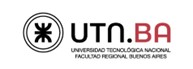

###**Trabajo Semanal 8**
**Teoria de los Circuitos 2**


Autor: Alan Nicolas Parizek


Profesor: Mariano Llamedo Soria  
Ayudante de TPs: David Moharos  
Jefe de TPs: César Fuoco  




##Consginas

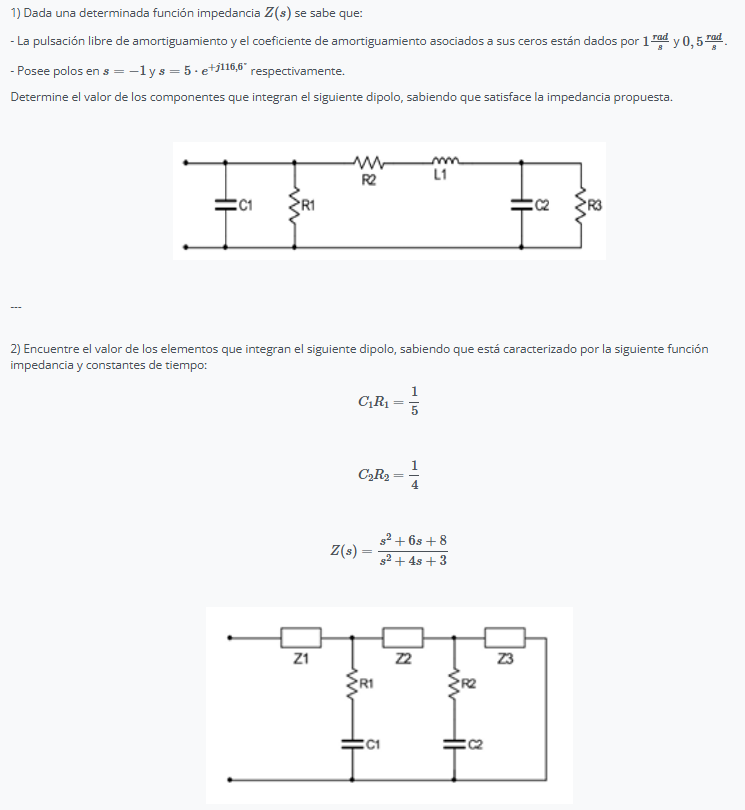

$$Z(s) = \frac{s^2 + s + 1}{(s + 1)(s^2 + 4{,}48s + 25)}$$

$$Y(s) = \frac{(s + 1)(s^2 + 4{,}48s + 25)}{s^2 + s + 1}$$

$$K_\infty = \lim_{s \to \infty} \frac{Y(s)}{s} = 1$$

$$Y_2 = \frac{(s + 1)(s^2 + 4{,}48s + 25)}{s^2 + s + 1} - s$$

$$Y_2 = \frac{s^3 + 4{,}48s^2 + 25s + s^2 + 4{,}48s + 25 - s^3 - s^2 - s}{s^2 + s + 1}$$

$$Y_2 = \frac{4{,}48s^2 + 28{,}48s + 25}{s^2 + s + 1}$$

$$G_1 = \lim_{s \to \infty} \frac{4{,}48s^2 + 28{,}48s + 25}{s^2 + s + 1} = 4{,}48$$

$$Y_3 = \frac{4{,}48s^2 + 28{,}48s + 25 - 4{,}48s^2 - 4{,}48s - 4{,}48}{s^2 + s + 1}$$

$$Y_3 = \frac{24s + 20{,}52}{s^2 + s + 1} \implies Z_3 = \frac{s^2 + s + 1}{24s + 20{,}52}$$

$$L_1 = \lim_{s \to \infty} \frac{Z_3(s)}{s} = \frac{s^2 + s + 1}{24s^2 + 20{,}52s} = \frac{1}{24}$$

$$Z_4 = \frac{s^2 + s + 1}{24(s + 0{,}855)} - \frac{s}{24}$$

$$Z_4 = \frac{s^2 + s + 1 - s^2 - 0{,}855s}{24(s + 0{,}855)}$$

$$Z_4 = \frac{0{,}145s + 1}{24(s + 0{,}855)}$$

$$R_2 = \lim_{s \to \infty} Z_4(s) \approx 0{,}006$$

$$Z_5 = \frac{0{,}145s + 1}{24(s + 0{,}855)} - 0{,}006$$

$$Z_5 = \frac{0{,}145s + 1 - 0{,}144s - 0{,}123}{24(s + 0{,}855)}$$

$$Z_5 = \frac{0{,}877}{24(s + 0{,}855)} = \frac{1}{27{,}36s + 23{,}39}$$

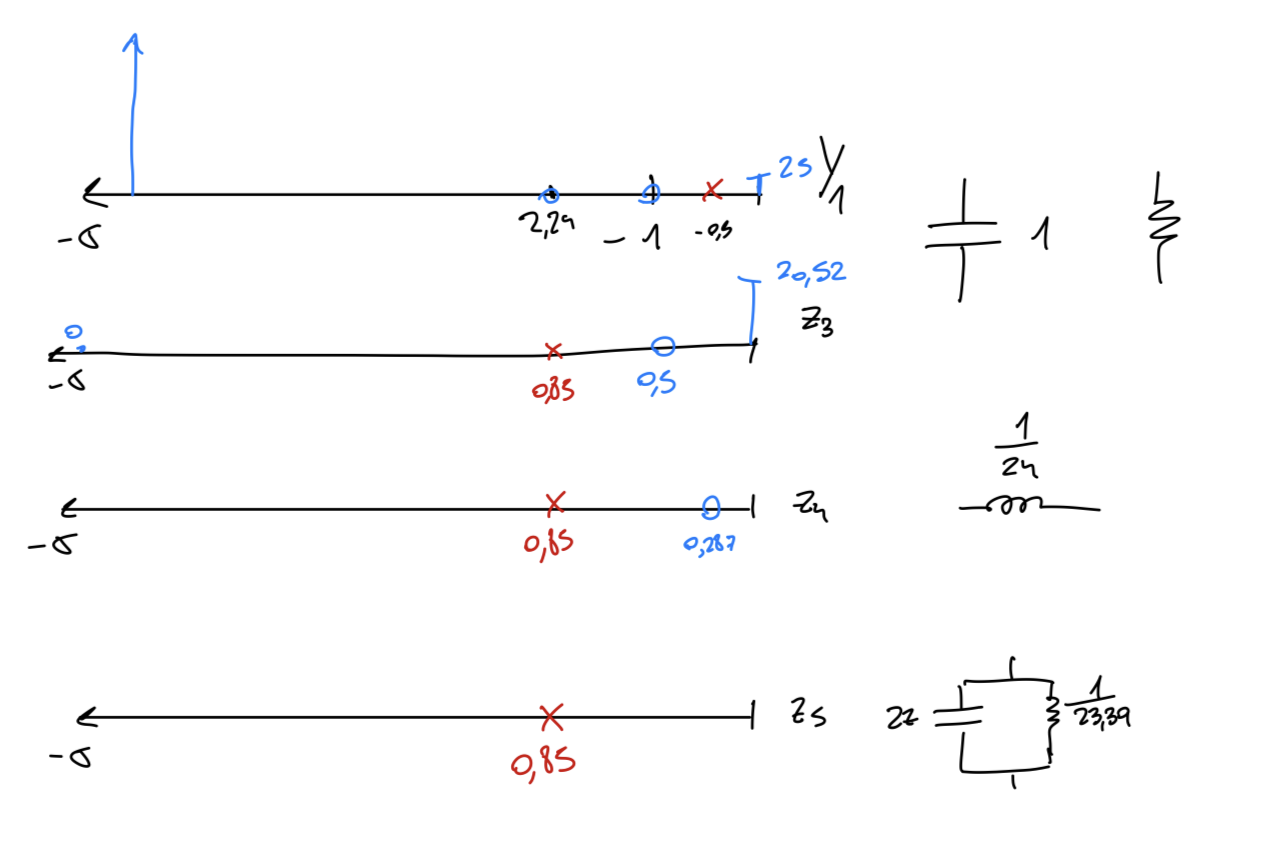

In [3]:
import sympy as sp
from schemdraw import Drawing

# Ahora importamos las funciones de PyTC2

from pytc2.remociones import remover_polo_dc, remover_polo_jw
from pytc2.dibujar import display, dibujar_puerto_entrada, dibujar_funcion_exc_abajo,  dibujar_elemento_serie, dibujar_elemento_derivacion,  dibujar_tanque_derivacion, dibujar_tanque_RC_serie,  dibujar_espacio_derivacion, Capacitor, Resistor, ResistorIEC
from pytc2.general import print_latex, print_subtitle
from IPython.display import display,  Markdown

# Importante importar símbolos de variables
from pytc2.general import s

###1

In [4]:
from pytc2.remociones import remover_valor_en_dc, remover_valor_en_infinito, remover_polo_sigma, remover_polo_infinito, remover_valor
Z = (s**2 + s + 1) / (s**3 + 5.48*s**2 + 29.48*s + 25)

Y2 , YC1 = remover_polo_infinito(1/Z)

print_latex(f"Y2(s) = {sp.latex(Y2)}")
print_latex(f"YC1(s) = {sp.latex(YC1)}")


<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [5]:
Y3 , YR1 = remover_valor_en_infinito(Y2)

print_latex(f"Y3(s) = {sp.latex(Y3)}")
print_latex(f"YR1(s) = {sp.latex(YR1)}")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [ ]:
#elimino la componente de coeficiente 2
Y3 = sp.nsimplify(Y3, tolerance=1e-10, rational=True)
Y3 = sp.cancel(sp.together(Y3))

Z4 , ZL1 = remover_polo_infinito(1/Y3)

print_latex(f"Z4(s) = {sp.latex(Z4)}")
print_latex(f"ZL1(s) = {sp.latex(ZL1)}")


<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [ ]:
Z5 , ZR2 = remover_valor_en_infinito(Z4)

print_latex(f"Z5(s) = {sp.latex(Z5)}")
print_latex(f"ZR2(s) = {sp.latex(ZR2)}")


In [ ]:
Y5 = 1/Z5
Y5 = sp.expand(sp.cancel(Y5))
C2 = Y5.coeff(s, 1)
G3 = Y5.coeff(s, 0)
R3 = 1/G3
print(float(C2), float(R3))

In [ ]:
import schemdraw as schdr
from schemdraw.elements import Capacitor, Resistor, Inductor
from pytc2.dibujar import (dibujar_puerto_entrada,
                           dibujar_elemento_derivacion,
                           dibujar_elemento_serie,
                           dibujar_puerto_salida,
                           dibujar_tanque_RC_derivacion)
C1 = YC1/s
L1 = ZL1/s


d = schdr.Drawing(unit=4)
d = dibujar_puerto_entrada(d)
d = dibujar_elemento_derivacion(d, Capacitor, C1)
d = dibujar_espacio_derivacion(d)
d = dibujar_espacio_derivacion(d)
d = dibujar_elemento_derivacion(d, Resistor, 1/YR1)
d = dibujar_elemento_serie(d, Resistor, ZR2)
d = dibujar_elemento_serie(d, Inductor, L1)
d = dibujar_elemento_derivacion(d, Capacitor, f'{float(C2):.2f}')
d = dibujar_espacio_derivacion(d)
d = dibujar_espacio_derivacion(d)
d = dibujar_elemento_derivacion(d, Resistor, f'{float(R3):.2f}')

display(d)

###2

$$Z = \frac{(s + 2)(s + 4)}{(s + 1)(s + 3)} = \frac{s^2 + 6s + 8}{s^2 + 4s + 3}$$

$$\lim_{s \to 0} \frac{s^2 + 6s + 8}{s^2 + 4s + 3} = \frac{8}{3} \implies Z_1 + Z_2 + Z_3 = \frac{8}{3}$$

$$\left. Z \right|_{s = -5} = \frac{(-5)^2 + 6(-5) + 8}{(-5)^2 + 4(-5) + 3} = \frac{3}{8} = Z_1$$

$$Z_2 = \frac{s^2 + 6s + 8}{s^2 + 4s + 3} - \frac{3}{8} = \frac{s^2 + 6s + 8 - \frac{3}{8}s^2 - \frac{3}{2}s - \frac{9}{8}}{s^2 + 4s + 3}$$

$$Z_2 = \frac{\frac{5}{8}s^2 + \frac{9}{2}s + \frac{55}{8}}{s^2 + 4s + 3} \implies Y_2 = \frac{s^2 + 4s + 3}{\frac{5}{8}s^2 + \frac{9}{2}s + \frac{55}{8}} = \frac{(s + 1)(s + 3)}{\frac{5}{8}(s + \frac{11}{5})(s + 5)}$$

$$K_1 = \lim_{s \to -5} \frac{(s + 5)}{s} \frac{(s + 1)(s + 3)}{\frac{5}{8}(s + \frac{11}{5})(s + 5)} = \frac{32}{35}$$

$$Y_{RC1} = \frac{\frac{32}{35}s}{s + 5} = \frac{1}{\frac{s + 5}{\frac{32}{35}s}} = \frac{1}{\frac{35}{32} + \frac{175}{32}\frac{1}{s}}$$

$$Y_3 = \frac{s^2 + 4s + 3}{\frac{5}{8}(s + \frac{11}{5})(s + 5)} - \frac{\frac{32}{35}s}{s + 5} = \frac{\frac{3}{7}(s + \frac{7}{5})(s + 5)}{\frac{5}{8}(s + \frac{11}{5})(s + 5)}$$

$$Y_3 = \frac{24}{35} \frac{s + \frac{7}{5}}{s + \frac{11}{5}} \implies Z_3 = \frac{35}{24} \frac{s + \frac{11}{5}}{s + \frac{7}{5}}$$

$$\left. Z_3 \right|_{s = -4} \approx 1 = Z_2$$

$$Z_4 = \frac{35}{24} \frac{s + \frac{11}{5}}{s + \frac{7}{5}} - 1 = \frac{35s + 77 - 24s - \frac{168}{5}}{24s + \frac{168}{5}} = \frac{11s + \frac{217}{5}}{24s + \frac{168}{5}}$$

$$Z_4 = \frac{11}{24} \frac{s + \frac{217}{55}}{s + \frac{7}{5}} \implies Y_4 = \frac{24}{11} \frac{s + \frac{7}{5}}{s + \frac{217}{55}} \approx \frac{24}{11} \frac{s + \frac{7}{5}}{s + 4}$$

$$K_2 = \lim_{s \to -4} \frac{s + 4}{s} \cdot \frac{24}{11} \frac{s + \frac{7}{5}}{s + 4} = \frac{78}{55}$$

$$Y_5 = \frac{24}{11} \frac{s + \frac{7}{5}}{s + 4} - \frac{\frac{78}{55}s}{s + 4} = \frac{\frac{42}{55}(s + 4)}{11(s + 4)} = \frac{42}{55}$$

$$Z_5 = \frac{55}{42}$$

$$Y_{RC2} = \frac{\frac{78}{55}s}{s + 4} = \frac{1}{\frac{55}{78} + \frac{220}{78}\frac{1}{s}}$$

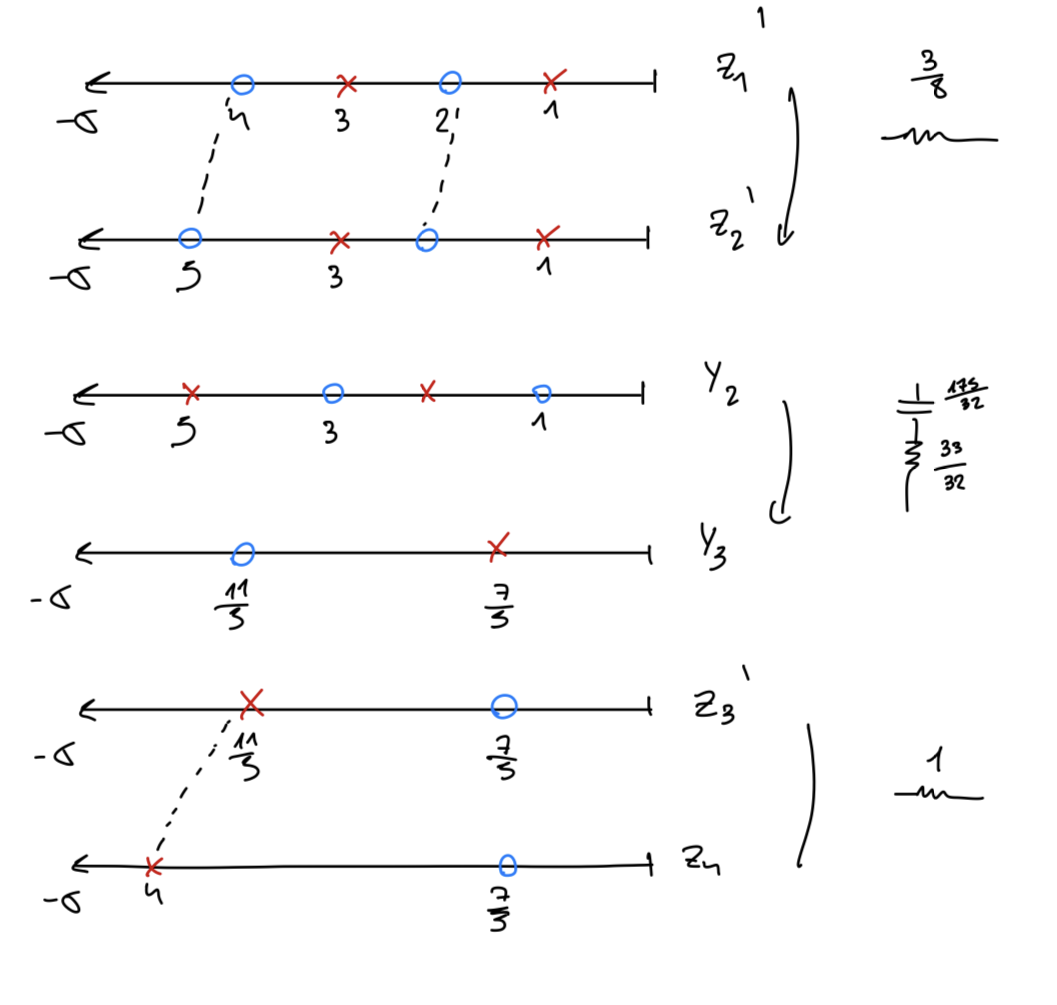

In [ ]:
sigma_R1C1 = 5

Z = (s**2 + 6*s + 8) / (s**2 + 4*s + 3)
ZB, Z1 = remover_valor(Z, sigma_zero=sigma_R1C1)

print_latex(f"ZB(s) = {sp.latex(ZB)}")
print_latex(f"Z1(s) = {sp.latex(Z1)}")

In [ ]:
r = remover_polo_sigma(1/ZB, sigma=5, isImpedance=False)

YC = r[0]
YRC1 = r[1]

print_latex(f"YC(s) = {sp.latex(YC)}")
print_latex(f"YRC1(s) = {sp.latex(YRC1)}")
t1 = sp.simplify(YRC1)

In [ ]:
R1 = sp.limit(1 / t1, s, sp.oo)
C1 = sp.limit(t1 / s, s, 0)

In [ ]:
sigma_R2C2 = 4

ZD, Z2 = remover_valor(1/YC, sigma_zero=sigma_R2C2)

print_latex(f"ZD(s) = {sp.latex(ZD)}")
print_latex(f"Z2(s) = {sp.latex(Z2)}")


In [ ]:
r = remover_polo_sigma(1/ZD, sigma=sigma_R2C2, isImpedance=False)

YE = r[0]
YR2C2 = r[1]

print_latex(f"YE(s) = {sp.latex(YE)}")
print_latex(f"YR2C2(s) = {sp.latex(YR2C2)}")
t2 = sp.simplify(YR2C2)

In [ ]:
R2 = sp.limit(1 / t2, s, sp.oo)
C2 = sp.limit(t2 / s, s, 0)

In [ ]:


d = schdr.Drawing(unit=4)
dibujar_puerto_entrada(d)
dibujar_elemento_serie(d, Resistor, Z1)
dibujar_tanque_RC_derivacion(d,  R1, C1)
dibujar_elemento_serie(d, Resistor, Z2)
dibujar_tanque_RC_derivacion(d, R2, C2)
d = dibujar_espacio_derivacion(d)
d = dibujar_espacio_derivacion(d)
dibujar_elemento_derivacion(d, Resistor, 1/YE)

d.draw()

##Verificacion Circuital

##1

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.signal as sig

# Coeficientes en potencias decrecientes de s:
# Por ejemplo, para Z(s) = (s^2 + 6s + 8) / (s^2 + 4s + 3)
num = [1, 1, 1]
den = [1, 5.48, 29.48, 25]

# Definición del sistema LTI (inmitancia del dipolo)
sistema = sig.TransferFunction(num, den)

# Rango de frecuencia angular omega (rad/s)
w = np.logspace(-2, 2, 1000)
w, mag, fase = sig.bode(sistema, w=w)

# Gráfica
fig, (ax_mag, ax_phase) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)

# Módulo |Z(jw)| en dB (o en Ohms si prefieres escala lineal)
ax_mag.semilogx(w, mag, color='royalblue', lw=1.8)
ax_mag.set_title(r'Respuesta en frecuencia del Dipolo: $Z(s)$', fontsize=13)
ax_mag.set_ylabel(r'$|Z(j\omega)|$ [dB]', fontsize=11)
ax_mag.grid(True, which='both', ls=':', alpha=0.6)

# Fase arg{Z(jw)} en grados
ax_phase.semilogx(w, fase, color='darkorange', lw=1.8)
ax_phase.set_xlabel(r'$\omega$ [rad/s]', fontsize=11)
ax_phase.set_ylabel(r'$\arg\{Z(j\omega)\}$ [°]', fontsize=11)
ax_phase.grid(True, which='both', ls=':', alpha=0.6)

plt.tight_layout()
plt.show()

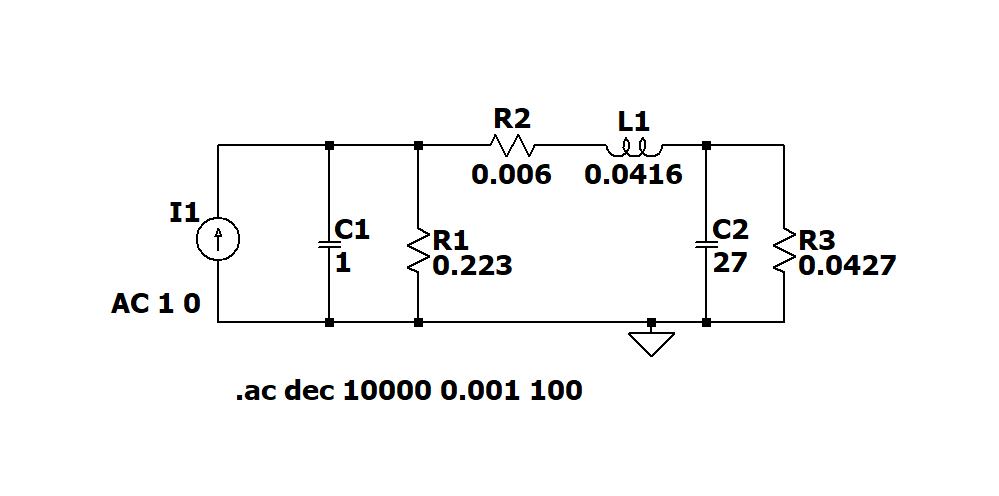

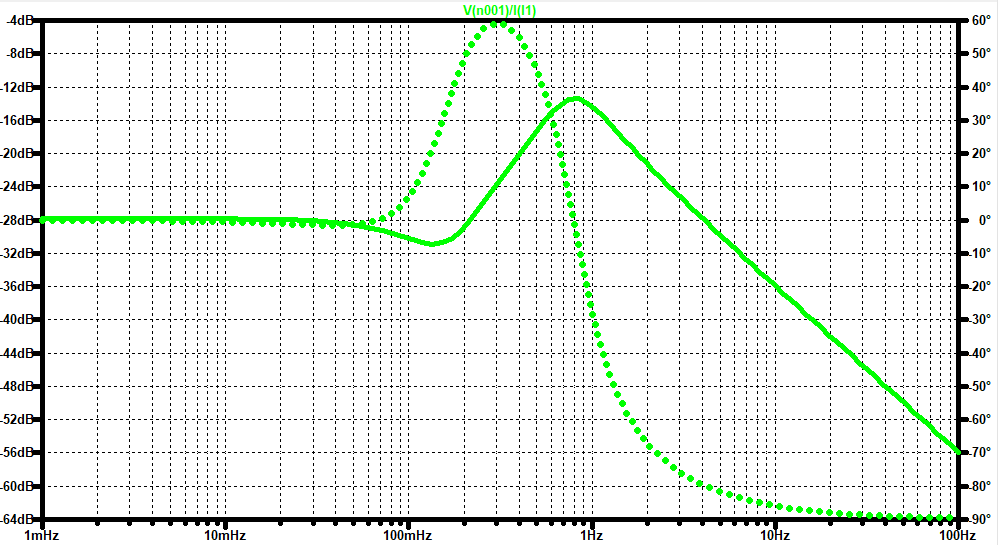

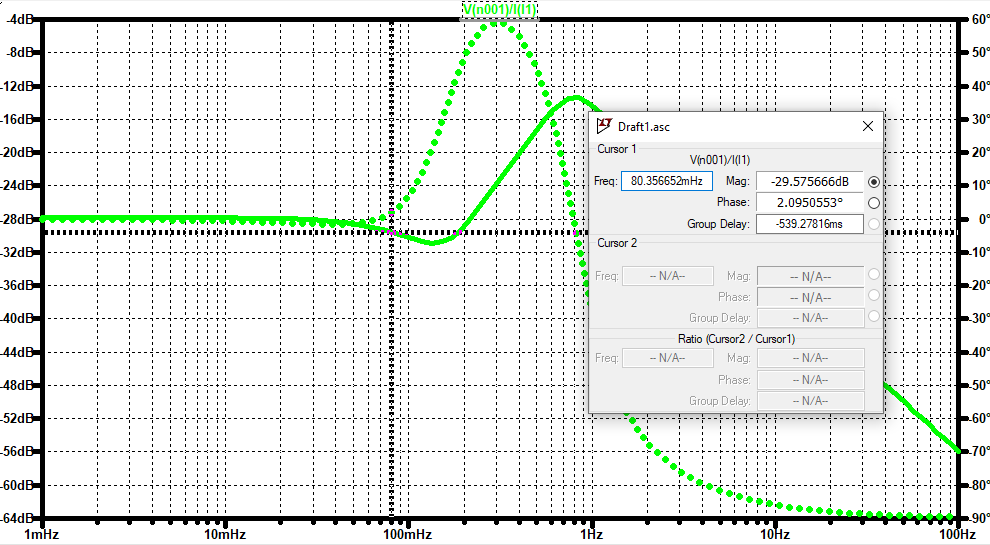

80mHz = 0,5r/s

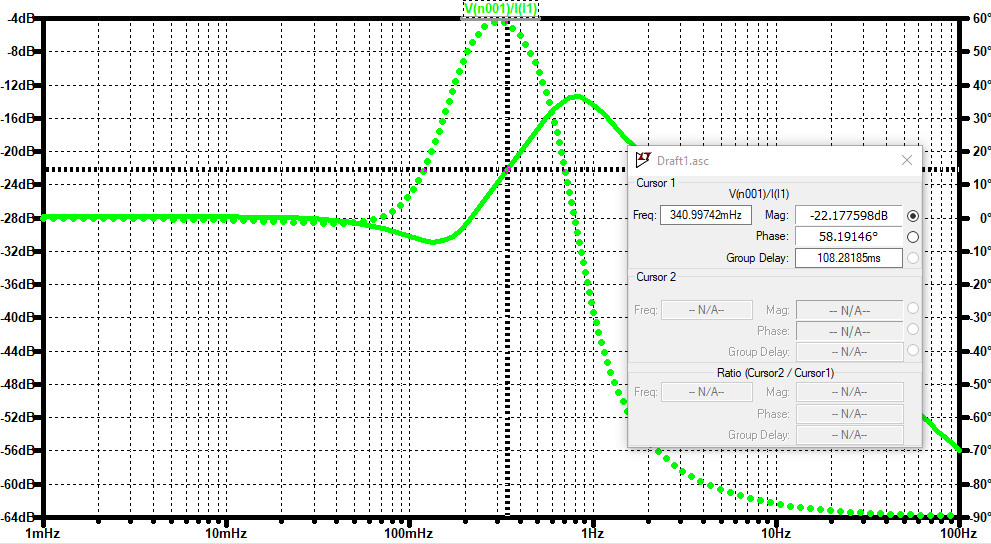

###2

In [ ]:
# Coeficientes en potencias decrecientes de s:
# Por ejemplo, para Z(s) = (s^2 + 6s + 8) / (s^2 + 4s + 3)
num = [1, 6, 8]
den = [1, 4, 3]

# Definición del sistema LTI (inmitancia del dipolo)
sistema = sig.TransferFunction(num, den)

# Rango de frecuencia angular omega (rad/s)
w = np.logspace(-2, 2, 1000)
w, mag, fase = sig.bode(sistema, w=w)

# Gráfica
fig, (ax_mag, ax_phase) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)

# Módulo |Z(jw)| en dB (o en Ohms si prefieres escala lineal)
ax_mag.semilogx(w, mag, color='royalblue', lw=1.8)
ax_mag.set_title(r'Respuesta en frecuencia del Dipolo: $Z(s)$', fontsize=13)
ax_mag.set_ylabel(r'$|Z(j\omega)|$ [dB]', fontsize=11)
ax_mag.grid(True, which='both', ls=':', alpha=0.6)

# Fase arg{Z(jw)} en grados
ax_phase.semilogx(w, fase, color='darkorange', lw=1.8)
ax_phase.set_xlabel(r'$\omega$ [rad/s]', fontsize=11)
ax_phase.set_ylabel(r'$\arg\{Z(j\omega)\}$ [°]', fontsize=11)
ax_phase.grid(True, which='both', ls=':', alpha=0.6)

plt.tight_layout()
plt.show()

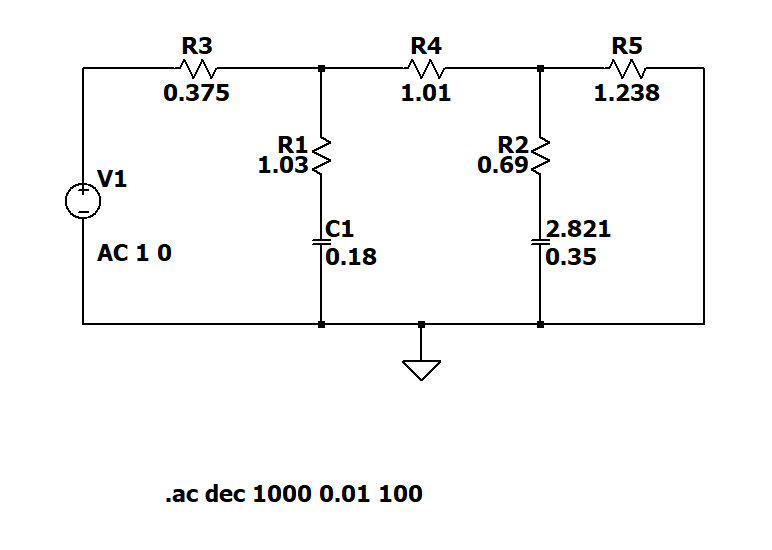

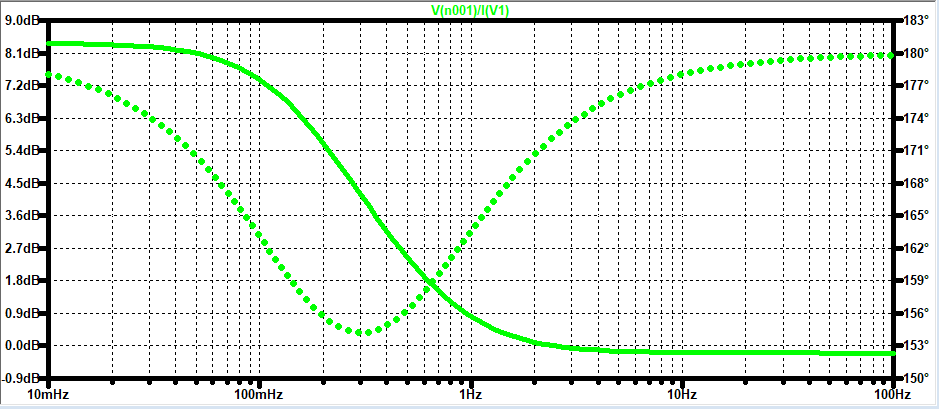

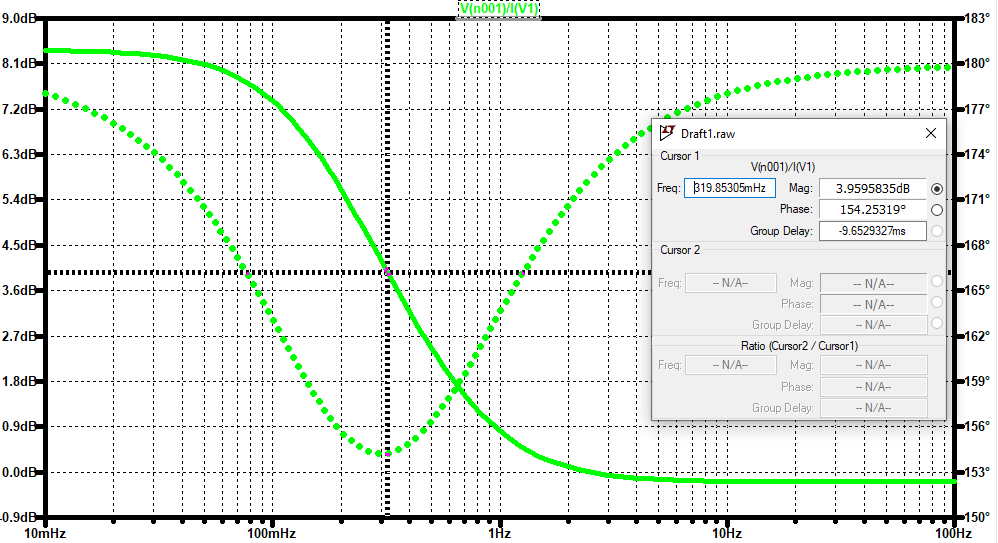